<a href="https://colab.research.google.com/github/D-LukeSherman/ECGR-4105/blob/main/Homework7/Homework7_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [123]:
import torch
import numpy as np
import pandas as pd
import torch.nn as nn
import matplotlib.pyplot as plt
import math
import seaborn as sns
import os
import imageio
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from torchvision import datasets

In [124]:
data_path = '../data-unversioned/'

cifar10 = datasets.CIFAR10(
  data_path,
  train = True,
  download = True,
)

cifar10_val = datasets.CIFAR10(
    data_path,
    train = False,
    download = True
)

In [125]:
len(cifar10)

50000

In [126]:
len(cifar10_val)

10000

In [127]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

In [128]:
img, label = cifar10[99]
img, label, class_names[label]

(<PIL.Image.Image image mode=RGB size=32x32>, 1, 'automobile')

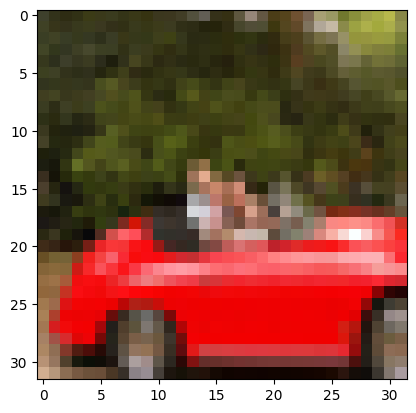

In [129]:
plt.imshow(img)
plt.show()

In [130]:
from torchvision import transforms

to_tensor = transforms.ToTensor()
img_t = to_tensor(img)
img_t.shape

torch.Size([3, 32, 32])

In [131]:
tensor_cifar10 = datasets.CIFAR10(
    root = data_path, train = True, download = False,
    transform = to_tensor
)

img_t, label = tensor_cifar10[99]
type(img_t), img_t.shape, img_t.dtype, label

(torch.Tensor, torch.Size([3, 32, 32]), torch.float32, 1)

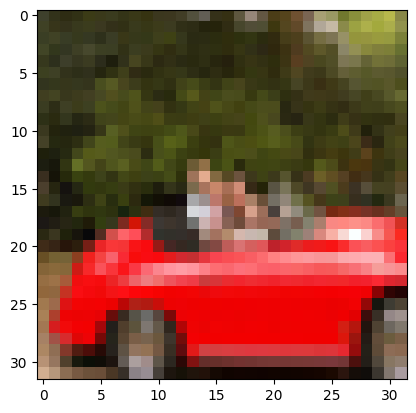

In [132]:
plt.imshow(img_t.permute(1, 2, 0))
plt.show()

In [133]:
imgs = torch.stack([img_t for img_t, _ in tensor_cifar10], dim=3)
imgs.shape

torch.Size([3, 32, 32, 50000])

In [134]:
imgs.view(3, -1).mean(dim=1)

tensor([0.4914, 0.4822, 0.4465])

In [135]:
imgs.view(3, -1).std(dim=1)

tensor([0.2470, 0.2435, 0.2616])

In [136]:
transformed_cifar10 = datasets.CIFAR10(
    data_path,
    train = True,
    download = False,
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(imgs.view(3, -1).mean(dim=1), imgs.view(3, -1).std(dim=1))
    ])
)

transformed_cifar10_val = datasets.CIFAR10(
    data_path,
    train = False,
    download = False,
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(imgs.view(3, -1).mean(dim=1), imgs.view(3, -1).std(dim=1))
    ])
)

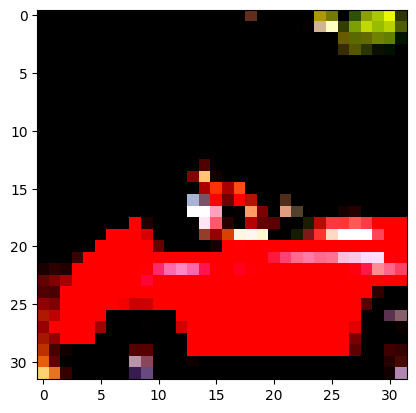

In [137]:
img_t, _ = transformed_cifar10[99]

plt.imshow(img_t.permute(1, 2, 0))
plt.show()

In [144]:
train_loader = torch.utils.data.DataLoader(
    transformed_cifar10,
    batch_size = 64,
    shuffle = True
)

model = nn.Sequential(
    nn.Linear(3072, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 10),
    nn.LogSoftmax(dim=1)
)

learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
loss_fn = nn.NLLLoss()
n_epochs = 60

In [146]:
import time

start_time = time.time()

for epoch in range(n_epochs):
  for imgs, labels in train_loader:
    batch_size = imgs.shape[0]
    out = model(imgs.view(batch_size, -1))
    loss = loss_fn(out, labels)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
  print("Epoch: %d, Loss: %f" % (epoch, loss.item()))

end_time = time.time()

Epoch: 0, Loss: 1.734139
Epoch: 1, Loss: 1.520815
Epoch: 2, Loss: 1.820485
Epoch: 3, Loss: 1.679533
Epoch: 4, Loss: 1.685995
Epoch: 5, Loss: 1.478665
Epoch: 6, Loss: 1.823838
Epoch: 7, Loss: 1.920282
Epoch: 8, Loss: 2.007367
Epoch: 9, Loss: 1.612681
Epoch: 10, Loss: 1.837495
Epoch: 11, Loss: 2.202870
Epoch: 12, Loss: 1.160506
Epoch: 13, Loss: 1.561799
Epoch: 14, Loss: 1.226822
Epoch: 15, Loss: 1.369405
Epoch: 16, Loss: 1.271176
Epoch: 17, Loss: 2.181312
Epoch: 18, Loss: 1.523157
Epoch: 19, Loss: 1.660513
Epoch: 20, Loss: 1.783001
Epoch: 21, Loss: 1.749767
Epoch: 22, Loss: 1.362452
Epoch: 23, Loss: 1.425609
Epoch: 24, Loss: 1.742182
Epoch: 25, Loss: 1.434179
Epoch: 26, Loss: 1.407029
Epoch: 27, Loss: 1.106390
Epoch: 28, Loss: 1.367918
Epoch: 29, Loss: 1.555522
Epoch: 30, Loss: 1.804410
Epoch: 31, Loss: 1.937674
Epoch: 32, Loss: 1.274059
Epoch: 33, Loss: 1.592308
Epoch: 34, Loss: 1.674564
Epoch: 35, Loss: 1.267956
Epoch: 36, Loss: 1.816975
Epoch: 37, Loss: 1.777521
Epoch: 38, Loss: 1.625

In [147]:
tensor_cifar10_v = datasets.CIFAR10(
    root = data_path, train = False, download = False,
    transform = to_tensor
)

In [148]:
train_loader = torch.utils.data.DataLoader(
    transformed_cifar10,
    batch_size = 64,
    shuffle = False
)

correct = 0
total = 0

with torch.no_grad():
  for imgs, labels in train_loader:
    batch_size = imgs.shape[0]
    outputs = model(imgs.view(batch_size, -1))
    _, predicted = torch.max(outputs, dim=1)
    total += labels.shape[0]
    correct += int((predicted == labels).sum())

  accuracy_t = correct / total

In [149]:
numel_list = [p.numel()
              for p in model.parameters()
              if p.requires_grad == True]
sum(numel_list), numel_list

(238922,
 [196608,
  64,
  4096,
  64,
  4096,
  64,
  4096,
  64,
  4096,
  64,
  4096,
  64,
  4096,
  64,
  4096,
  64,
  4096,
  64,
  4096,
  64,
  4096,
  64,
  640,
  10])

In [150]:
val_loader = torch.utils.data.DataLoader(
    transformed_cifar10_val,
    batch_size = 64,
    shuffle = False
)

correct = 0
total = 0

with torch.no_grad():
  for imgs, labels in val_loader:
    batch_size = imgs.shape[0]
    outputs = model(imgs.view(batch_size, -1))
    _, predicted = torch.max(outputs, dim=1)
    total += labels.shape[0]
    correct += int((predicted == labels).sum())

accuracy_v = correct / total
print("Time taken: %f" % (end_time - start_time))
print("Training Accuracy: %f", accuracy_t)
print("Evaluation Accuracy: %f", accuracy_v)
print("Number of Parameters: %f", sum(numel_list))

Time taken: 1009.531468
Training Accuracy: %f 0.52292
Evaluation Accuracy: %f 0.4478
Number of Parameters: %f 238922
